<a href="https://colab.research.google.com/github/jberisso/BA305-A1---hotel-bookings/blob/main/01_descriptive_question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Our descriptive question is: Do bookings at City Hotels and Resort Hotels have distinct profiles based on lead time, price, party size, and special requests, or are they more similar when these characteristics are considered together?

If the two hotels' bookings separate clearly, the properties attract different kinds of guests. If they overlap, their bookings have more in common than the different property types would suggest.

We looked at this dataset from the point of view of a commercial director at a hotel group that owns both properties: a city hotel in Lisbon and a resort in the Algarve. While planning next year's budget, the director has to choose between one marketing and revenue-management team for both hotels (shared campaigns, shared early-booking promotions, one pricing approach) or two separate teams.

One team is cheaper, but it only works if the two hotels get similar bookings. So the decision depends on our answers:
- If the booking profiles are clearly different, each hotel needs its own team and strategy.
- If they overlap a lot, one team makes sense, and only the parts that still differ need to be handled separately.

In [39]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


1. Data-quality check - Before doing any analysis we checked for values that can't be right or that could distort the results.

In [40]:
checks = {
    'missing children': df['children'].isna().sum(),
    'negative ADR': (df['adr'] < 0).sum(),
    'ADR of exactly 0': (df['adr'] == 0).sum(),
    'no guests (adults + children + babies = 0)': ((df['adults'] + df['children'].fillna(0) + df['babies']) == 0).sum(),
    'more than 10 adults': (df['adults'] > 10).sum(),
    'exact duplicate rows': df.duplicated().sum(),
}
print('total bookings:', len(df))
pd.Series(checks, name='bookings').to_frame()

total bookings: 119390


,bookings
missing children,4
negative ADR,1
ADR of exactly 0,1959
no guests (adults + children + babies = 0),180
more than 10 adults,12
exact duplicate rows,31994


Most of these problems are small. Only 4 bookings are missing the number of children, 1 has a negative rate, and 12 have more than 10 adults. Two are bigger: 1,959 bookings (1.6%) have a rate of exactly $0, and 180 bookings (0.15%) list no guests at all, which can't be a real stay.

The biggest issue is duplicates. 31,994 rows (26.8% of the data) are exact copies of another row. The dataset has no booking ID, so we can't tell for sure, but these are most likely several rooms booked together as part of a group. Every field is identical, including the arrival date, lead time and price.

We don't delete these rows straight away. Some of them are probably real (a \$0 rate could be a complimentary stay, and identical rows are likely separate rooms in the same group booking). For a descriptive question each room is still real demand, so we keep the duplicates. We flag the other problems here and remove only the most extreme cases, the ones that would distort PCA, in step 3.

2. Looking at all five variables together (PCA)

We picked five variables that cover the four parts of our question: **lead time** (timing), **ADR** (price), **adults** and **children** (party size), and **total special requests** (guest needs).

The variables are on very different scales. ADR is in the hundreds, while children is usually 0 or 1. PCA is sensitive to scale, so we standardized everything first. Otherwise ADR would dominate just because its numbers are bigger.

We then used PCA to reduce the five variables to two components (PC1 and PC2), so each booking can be plotted as one point.

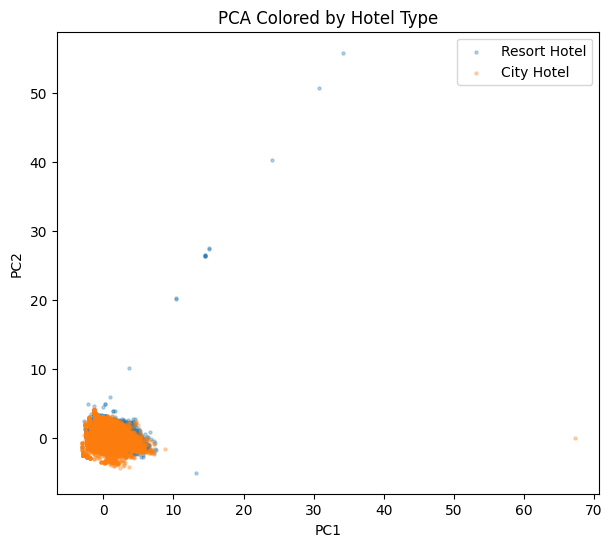

Explained variance ratio: [0.30273916 0.22357076]


In [41]:
features = ['lead_time', 'adr', 'adults', 'children', 'total_of_special_requests']
pca_data = df[features].fillna(0)

scaled = StandardScaler().fit_transform(pca_data)

pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled)

plt.figure(figsize=(7, 6))
for h in df['hotel'].unique():
    mask = df['hotel'] == h
    plt.scatter(pcs[mask, 0], pcs[mask, 1], label=h, alpha=0.3, s=5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.title('PCA Colored by Hotel Type')
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)

The first two components explain 52.6% of the total variance (30.3% and 22.4%). The two hotels' points sit on top of each other, but a few points far out on PC1 stretch the plot, so we looked at those next.

3. Extreme bookings

In [42]:
pca_df = pd.DataFrame(pcs, columns=['PC1', 'PC2'], index=pca_data.index)
outliers = pca_df.sort_values('PC1', ascending=False).head(10)
df.loc[outliers.index, features + ['hotel', 'is_canceled']]

,lead_time,adr,adults,children,total_of_special_requests,hotel,is_canceled
48515,35,5400.0,2,0.0,0,City Hotel,1
2173,338,0.0,55,0.0,0,Resort Hotel,1
1643,336,0.0,50,0.0,0,Resort Hotel,1
1539,304,0.0,40,0.0,0,Resort Hotel,1
1917,349,0.0,27,0.0,0,Resort Hotel,1
1962,352,0.0,27,0.0,0,Resort Hotel,1
1587,333,0.0,26,0.0,0,Resort Hotel,1
1752,340,0.0,26,0.0,0,Resort Hotel,1
1884,347,0.0,26,0.0,0,Resort Hotel,1
2003,354,0.0,26,0.0,0,Resort Hotel,1


The ten most extreme bookings on PC1 are clearly data problems, not real guests. One City Hotel booking has a nightly rate of \$5,400. The other nine are Resort Hotel bookings for 26 to 55 adults at \$0 a night, made more than 300 days in advance. All ten were canceled.

We removed these ten and reran PCA to check whether they were changing the results.

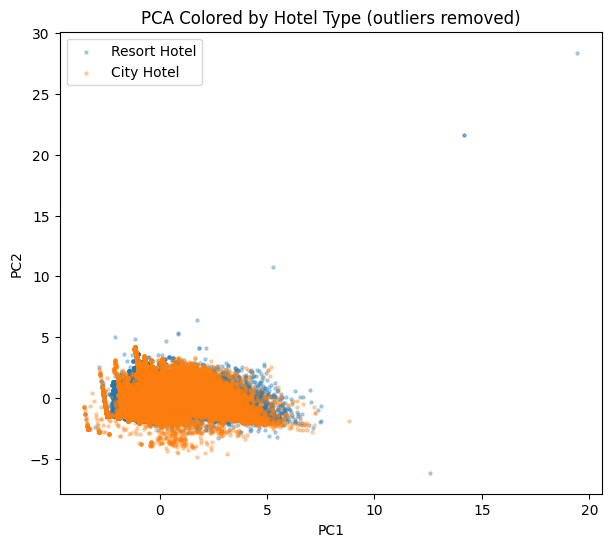

Explained variance ratio (outliers removed): [0.31415513 0.22390533]


In [43]:
clean_data = df.drop(index=outliers.index)
pca_data_clean = clean_data[features].fillna(0)
scaled_clean = StandardScaler().fit_transform(pca_data_clean)

pca_clean = PCA(n_components=2)
pcs_clean = pca_clean.fit_transform(scaled_clean)

plt.figure(figsize=(7, 6))
for h in clean_data['hotel'].unique():
    mask = clean_data['hotel'] == h
    plt.scatter(pcs_clean[mask, 0], pcs_clean[mask, 1], label=h, alpha=0.3, s=5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.title('PCA Colored by Hotel Type (outliers removed)')
plt.show()

print("Explained variance ratio (outliers removed):", pca_clean.explained_variance_ratio_)

Without the ten outliers, the first two components explain 53.8% of the variance (31.4% and 22.4%), only about one percentage point more than before. The outliers were stretching the plot but not changing its structure. From here on we use the cleaned data.

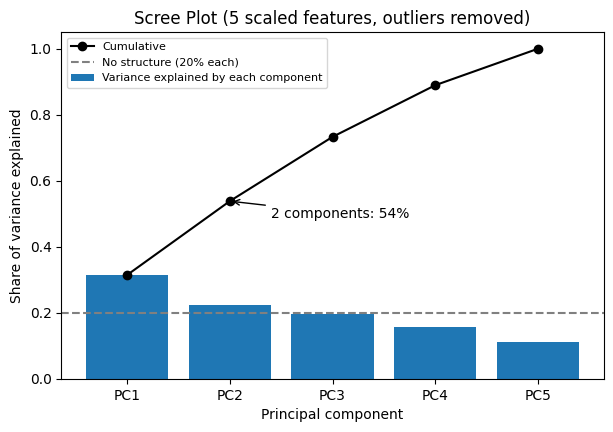

,explained,cumulative
PC1,0.314,0.314
PC2,0.224,0.538
PC3,0.195,0.733
PC4,0.157,0.889
PC5,0.111,1.000


In [44]:
import numpy as np
#scree plot to choose number of components
pca_full = PCA().fit(scaled_clean)
ratios = pca_full.explained_variance_ratio_
cumulative = ratios.cumsum()
n = np.arange(1, len(ratios) + 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(n, ratios, label='Variance explained by each component')
ax.plot(n, cumulative, marker='o', color='black', label='Cumulative')
ax.axhline(1 / len(features), color='grey', linestyle='--',
           label=f'No structure ({1 / len(features):.0%} each)')
ax.annotate(f'2 components: {cumulative[1]:.0%}', (2, cumulative[1]),
            xytext=(2.4, cumulative[1] - 0.05), arrowprops={'arrowstyle': '->'})
ax.set_xticks(n); ax.set_xticklabels([f'PC{i}' for i in n])
ax.set_xlabel('Principal component'); ax.set_ylabel('Share of variance explained')
ax.set_ylim(0, 1.05); ax.legend(loc='upper left', fontsize=8)
ax.set_title('Scree Plot (5 scaled features, outliers removed)')
plt.show()

display(pd.DataFrame({'explained': ratios, 'cumulative': cumulative},
                     index=[f'PC{i}' for i in n]).round(3))

Scree plot shows no clear 'elbow', but only PC1 and 2 are above the 'no structure' line, so we decided to just use the first two for our analysis.


4. What the two componets mean

In [45]:
components_df = pd.DataFrame(
    pca_clean.components_,
    columns=features,
    index=['PC1', 'PC2']
)
print(components_df.round(3))

# Which single feature contributes most to each component?
for pc in components_df.index:
    top_feature = components_df.loc[pc].abs().idxmax()
    print(f'{pc} is most driven by: {top_feature} (loading = {components_df.loc[pc, top_feature]:.3f})')



     lead_time    adr  adults  children  total_of_special_requests
PC1     -0.072  0.644   0.443     0.475                      0.398
PC2      0.790 -0.017   0.544    -0.236                     -0.155
PC1 is most driven by: adr (loading = 0.644)
PC2 is most driven by: lead_time (loading = 0.790)


**PC1** has positive loadings on ADR (0.644), children (0.475), adults (0.443), and special requests (0.398). It roughly measures how big and how expensive a booking is: larger parties that pay more and ask for more.

**PC2** is mostly lead time (0.790) and adults (0.544). It picks up larger groups that book far in advance.

So if the two hotels really had different booking profiles, we would expect one of them to sit further along PC1 (bigger, more expensive bookings) or PC2 (groups booking early).

5. Comparing the two hotels in PCA space

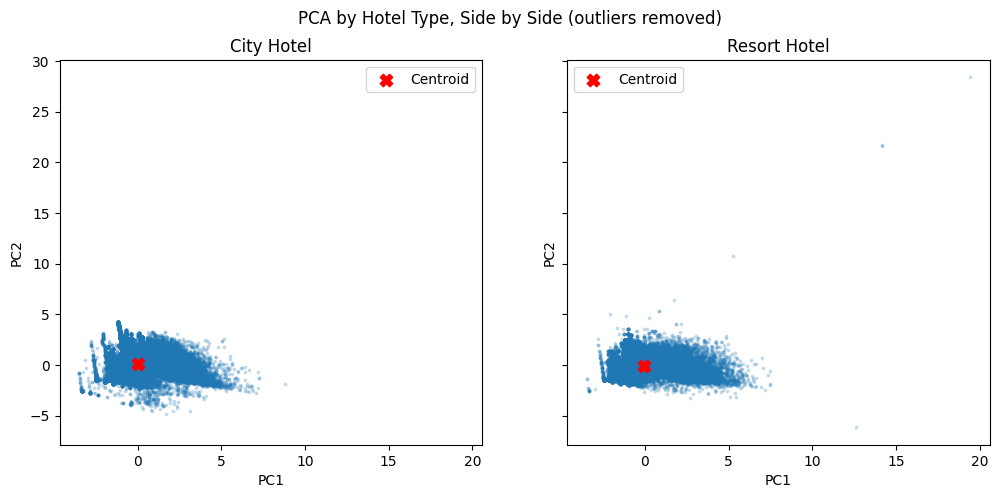

PC1         PC2      
              mean   std  mean   std
hotel                               
City Hotel    0.01  1.15  0.05  1.09
Resort Hotel -0.02  1.44 -0.10  0.98

In [46]:
pc_df = pd.DataFrame(pcs_clean, columns=['PC1', 'PC2'], index=clean_data.index)
pc_df['hotel'] = clean_data['hotel']

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, h in zip(axes, ['City Hotel', 'Resort Hotel']):
    sub = pc_df[pc_df['hotel'] == h]
    ax.scatter(sub['PC1'], sub['PC2'], s=3, alpha=0.2)
    ax.scatter(sub['PC1'].mean(), sub['PC2'].mean(), color='red', s=80, marker='X', label='Centroid')
    ax.set_title(h); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend()
plt.suptitle('PCA by Hotel Type, Side by Side (outliers removed)')
plt.show()

pc_df.groupby('hotel')[['PC1', 'PC2']].agg(['mean', 'std']).round(2)

In the first scatterplot the City Hotel points were drawn on top of the Resort points, which made it hard to see how much they overlap. Plotting each hotel in its own panel on the same axes fixes that, and both hotels clearly cover the same area.

The centroids (red X) are 0.03 apart on PC1 (0.01 vs. –0.02) and 0.15 apart on PC2 (0.05 vs. –0.10). Within each hotel, the standard deviation on each component is between about 1.0 and 1.4. So the difference between the two hotels' average bookings is roughly a tenth of the variation among bookings at the same hotel.

Resort bookings are a bit more spread out on PC1 (std 1.44 vs. 1.15) and include a few extreme points, but most bookings at both hotels look the same.

6. Comparing each variable on its own

In [47]:
features = ['lead_time', 'adr', 'adults', 'children', 'total_of_special_requests']
df.groupby('hotel')[features].agg(['mean', 'median', 'std']).round(2)

lead_time                    adr               adults         \
                  mean median     std    mean median    std   mean median   
hotel                                                                       
City Hotel      109.74   74.0  110.95  105.30   99.9  43.60   1.85    2.0   
Resort Hotel     92.68   57.0   97.29   94.95   75.0  61.44   1.87    2.0   

                   children              total_of_special_requests         \
               std     mean median   std                      mean median   
hotel                                                                       
City Hotel    0.51     0.09    0.0  0.37                      0.55    0.0   
Resort Hotel  0.70     0.13    0.0  0.45                      0.62    0.0   

                    
               std  
hotel               
City Hotel    0.78  
Resort Hotel  0.81

On average, City Hotel bookings are made earlier (109.7 vs. 92.7 days) and cost more per night (\$105.30 vs. \$94.95). Party size and special requests are almost the same at both hotels.

The averages don't tell the whole story, though. Lead time has a standard deviation of about 111 days at the City Hotel and 97 days at the Resort, while the gap between the two averages is only 17 days. Within each hotel, bookings vary much more than the difference between the hotels.

How big are these differences?

With about 119,000 bookings, almost any difference will be "statistically significant", even a tiny one. So instead of a significance test we measured how *big* each difference is, using the standardized mean difference (Cohen's d): the gap between the two hotels' means divided by the pooled standard deviation. A common rule of thumb is that 0.2 is small, 0.5 is medium, and 0.8 is large.

In [48]:
city = clean_data[clean_data['hotel'] == 'City Hotel']
resort = clean_data[clean_data['hotel'] == 'Resort Hotel']

rows = []
for col in features:
    a, b = city[col].dropna(), resort[col].dropna()
    pooled_sd = (((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2)) ** 0.5
    rows.append({'variable': col, 'City mean': a.mean(), 'Resort mean': b.mean(),
                 "Cohen's d": (a.mean() - b.mean()) / pooled_sd})
pd.DataFrame(rows).set_index('variable').round(2)

,City mean,Resort mean,Cohen's d
variable,,,
lead_time,109.74,92.62,0.16
adr,105.24,94.97,0.21
adults,1.85,1.86,-0.02
children,0.09,0.13,-0.09
total_of_special_requests,0.55,0.62,-0.09


All five differences are small. Price (d = 0.21) is the only one that reaches the 0.2 threshold for a small effect, and lead time (d = 0.16) is just below it. Adults, children and special requests are close to zero (d between –0.02 and –0.09), so the two hotels are practically the same on party size and guest requests. None of the variables comes anywhere near a medium effect (0.5).

This supports what the PCA showed: the hotels differ a little in timing and price, but not enough to give them distinct booking profiles. One caution is that Cohen's d compares means over the whole year. Step 7 shows that the price difference is much larger in some months than others, so the yearly number understates how differently the two hotels price at specific times of year.

Lead time and price are heavily right-skewed, so we used notched box plots instead of bar charts of means. We also decided to use log scale to help visualise the entire distribution. If the notches of two boxes don't overlap, their medians are different, but the boxes show how much the typical bookings overlap.

Party size and special requests only take a few whole-number values, so for those we compared the share of bookings in each category.

Price panel leaves out 1,951 bookings with ADR <= 0 (1.6% of bookings)


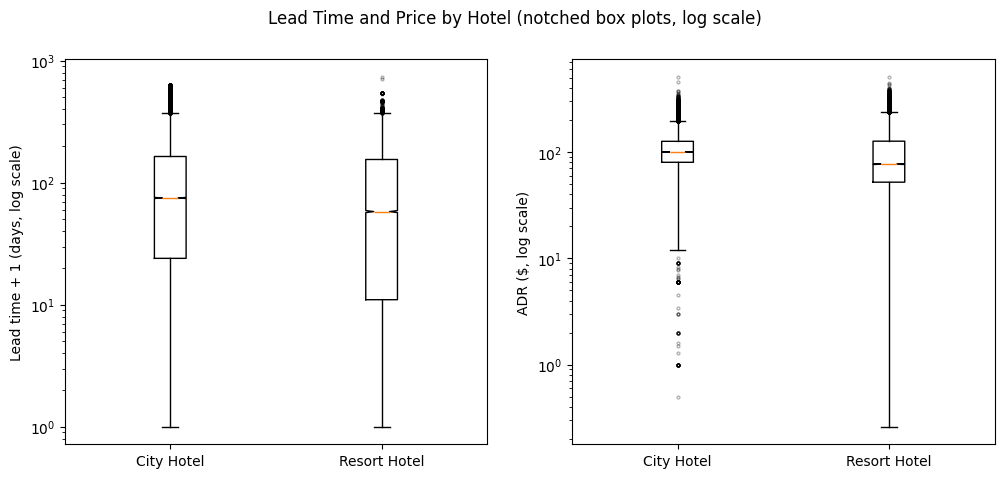

hotel,City Hotel,Resort Hotel
lead time (days) 25%,23.0,10.0
lead time (days) 50%,74.0,57.0
lead time (days) 75%,163.0,154.0
"ADR ($, ADR > 0 only) 25%",80.0,52.0
"ADR ($, ADR > 0 only) 50%",100.0,76.8
"ADR ($, ADR > 0 only) 75%",126.0,126.4


Party size (5 = 5 or more), share of bookings:


col_0,0.0,1.0,2.0,3.0,4.0,5.0
hotel,,,,,,
City Hotel,0.002,0.196,0.683,0.094,0.023,0.001
Resort Hotel,0.000,0.175,0.713,0.061,0.049,0.001


Special requests, share of bookings:


total_of_special_requests,0,1,2,3,4,5
hotel,,,,,,
City Hotel,0.605,0.270,0.103,0.020,0.002,0.0
Resort Hotel,0.558,0.295,0.121,0.023,0.004,0.0


In [49]:
# Box plots, shown in log scale
hotels = ['City Hotel', 'Resort Hotel']

# Log scales cannot show 0 or negative values:
# lead time is shifted by +1 day (same-day bookings have lead time 0),
# and bookings with ADR <= 0 (free or refunded stays) are left out of the price panel.
lead_plot = clean_data['lead_time'] + 1
adr_mask = clean_data['adr'] > 0
print(f"Price panel leaves out {(~adr_mask).sum():,} bookings with ADR <= 0 "
      f"({(~adr_mask).mean():.1%} of bookings)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
panels = [
    (axes[0], lead_plot, 'Lead time + 1 (days, log scale)'),
    (axes[1], clean_data['adr'].where(adr_mask), 'ADR ($, log scale)'),
]
for ax, values, label in panels:
    data = [values[clean_data['hotel'] == h].dropna() for h in hotels]
    ax.boxplot(data, notch=True, flierprops={'markersize': 2, 'alpha': 0.3})
    ax.set_yscale('log')
    ax.set_xticks([1, 2]); ax.set_xticklabels(hotels)
    ax.set_ylabel(label)
plt.suptitle('Lead Time and Price by Hotel (notched box plots, log scale)')
plt.show()

# Quartiles per hotel, on the original scale
quartiles = lambda s: s.groupby(clean_data['hotel']).quantile([0.25, 0.5, 0.75]).unstack()
summary = pd.concat({'lead time (days)': quartiles(clean_data['lead_time']),
                     'ADR ($, ADR > 0 only)': quartiles(clean_data['adr'].where(adr_mask))}, axis=1)
summary.columns = [f'{var} {q:.0%}' for var, q in summary.columns]
display(summary.round(1).T)

# Discrete variables: share of bookings in each category
party = (clean_data['adults'] + clean_data['children'].fillna(0)).clip(upper=5)
print("Party size (5 = 5 or more), share of bookings:")
display(pd.crosstab(clean_data['hotel'], party, normalize='index').round(3))
print("Special requests, share of bookings:")
display(pd.crosstab(clean_data['hotel'], clean_data['total_of_special_requests'], normalize='index').round(3))

**Lead time:** The two hotels overlap almost completely. The City Hotel's median (74 days) is higher than the Resort's (57 days), and the notches don't overlap, so the difference is real. But the middle 50% of bookings runs from about 23 to 163 days at the City Hotel and 10 to 155 days at the Resort, which is nearly the same range.

**Price (ADR):** This is the biggest difference. The Resort's median rate (\$75) is about \$25 below the City Hotel's (\$99.90), a bigger gap than the \$10 difference in means. Resort prices are also more spread out (standard deviation \$61 vs. \$44). The middle 50% runs from about \$50 to \$125 at the Resort and \$79 to \$126 at the City Hotel. The Resort's lower whisker goes below \$0, so there is at least one booking with a negative rate.

**Party size:** Almost the same. Two-person bookings are 68% of City Hotel bookings and 71% of Resort bookings. The Resort has a few more four-person bookings (4.9% vs. 2.3%), probably families, but the overall pattern is the same.

**Special requests:** Also almost the same. Most bookings at both hotels have no special requests (61% City, 56% Resort), and the shares with one, two or three requests are within a few percentage points.

Overall, guests at both hotels come in similar party sizes, ask for similar things and book on similar timelines. Price is the one place where the hotels clearly differ.

7. Does this hold across the year?

An overall comparison can hide differences that only show up at certain times of year. Since both hotels are in a tourist country, we compared median price and lead time by arrival month.

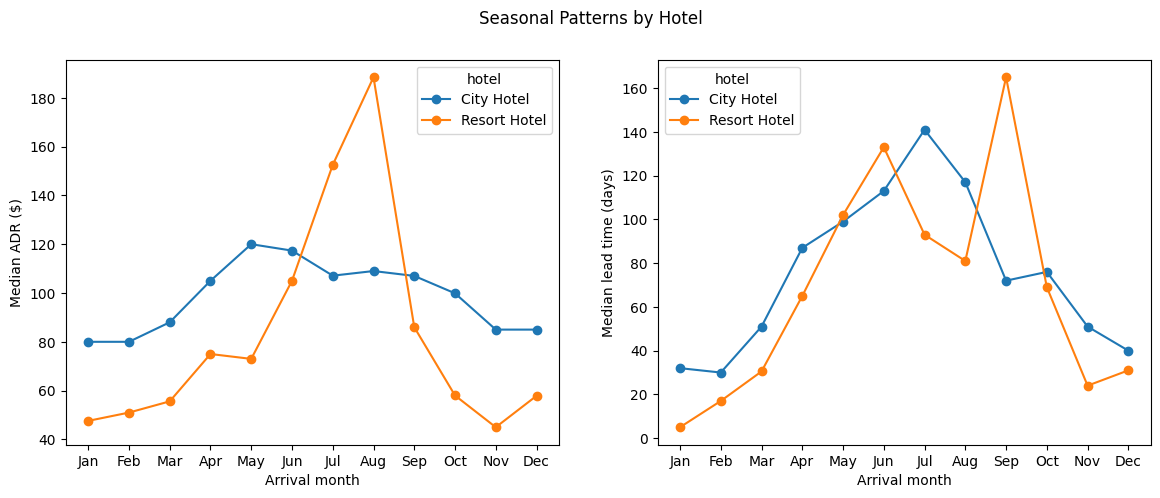

In [50]:
months = ['January','February','March','April','May','June','July',
          'August','September','October','November','December']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, label in zip(axes, ['adr', 'lead_time'], ['Median ADR ($)', 'Median lead time (days)']):
    clean_data.groupby(['arrival_date_month', 'hotel'])[col].median().unstack().reindex(months).plot(ax=ax, marker='o')
    ax.set_xticks(range(12)); ax.set_xticklabels([m[:3] for m in months])
    ax.set_ylabel(label); ax.set_xlabel('Arrival month')
plt.suptitle('Seasonal Patterns by Hotel')
plt.show()

**Price:** The two hotels price very differently over the year. The City Hotel stays between about \$80 and \$120 all year, with a small peak in May. The Resort goes from about \$47 in January to about \$188 in August, roughly four times higher, and then drops below \$60 from October on. The Resort is cheaper than the City Hotel in ten of the twelve months but much more expensive in July (\$152 vs. \$107) and August (\$188 vs. \$109). So the overall \$25 gap in medians is misleading. The real difference is that the Resort's prices follow the beach season and the City Hotel's don't.

**Lead time:** Here the two hotels move together. At both, guests book a few weeks ahead for winter stays and several months ahead for summer, with lead times peaking between June and September. The one exception is September arrivals at the Resort (165 days vs. 72 at the City Hotel), which may be large groups booking early.

So the similarity in booking behavior holds through the year. The one variable that differs, price, differs in a predictable way: the Resort has a sharp summer peak and the City Hotel doesn't.

8. Robustness check: canceled vs. completed bookings

About 37% of bookings in the data were canceled. If canceled bookings looked very different from completed ones, they could be hiding or creating a difference between the hotels. So we repeated the comparison of medians separately for completed and canceled bookings.

In [51]:
summary = clean_data.groupby(['is_canceled', 'hotel'])[features].median().round(1)
summary.index = summary.index.set_levels(['completed', 'canceled'], level=0)
summary

lead_time   adr  adults  children  \
is_canceled hotel                                             
completed   City Hotel         50.0  99.9     2.0       0.0   
            Resort Hotel       38.0  72.0     2.0       0.0   
canceled    City Hotel        115.0  99.8     2.0       0.0   
            Resort Hotel      108.0  84.0     2.0       0.0   

                          total_of_special_requests  
is_canceled hotel                                    
completed   City Hotel                          1.0  
            Resort Hotel                        0.0  
canceled    City Hotel                          0.0  
            Resort Hotel                        0.0

The comparison between the hotels looks the same whether we use completed or canceled bookings. In both groups, City Hotel bookings are made somewhat earlier and cost more, while party size is identical (2 adults, 0 children at both hotels). Including canceled bookings therefore doesn't create or hide a difference between the hotels.

The price gap is larger among completed bookings (\$99.90 vs. \$72) than among canceled ones (\$99.80 vs. \$84), so guests who actually stay at the Resort tend to pay less. Medians for special requests differ slightly (1 vs. 0 among completed bookings), but because this variable only takes a few whole numbers, a small shift in the share of bookings can move the median from 0 to 1.

The biggest difference in this table isn't between the hotels at all. It's between canceled and completed bookings. Canceled bookings were made much further in advance at both hotels (median 115 and 108 days) than completed ones (50 and 38 days). This gap is far bigger than any difference between the two hotels, and it is the starting point for our predictive question: how well lead time predicts cancellations.

Looking at lead time, price, party size and special requests together, City and Resort Hotel bookings are **more similar than distinct**.

- In the PCA, both hotels cover the same area. Their centroids differ by only 0.03 on PC1 and 0.15 on PC2, compared with within-hotel standard deviations of about 1.0 to 1.4.
- One variable at a time, party size and special requests are nearly identical, and lead times overlap almost completely and follow the same seasonal pattern at both hotels.
- The result holds when we look only at completed bookings or only at canceled ones, so it isn't caused by including cancellations.
- The one clear difference is price. The Resort's rates rise about fourfold from winter to its July–August peak, while the City Hotel's stay fairly stable all year.

**Recommendation for the commercial director:** use one marketing team for both hotels, but price each hotel separately. Both hotels attract the same kind of booking, mostly couples with few special requests, and guests book on the same seasonal calendar: a few weeks ahead for winter and months ahead for summer. That supports shared campaigns, shared targeting, and early-booking promotions launched together in late winter and spring, and it saves the cost of a second team. Pricing is the exception. The Resort needs strong seasonal pricing, with discounts from October to May and higher rates in July and August, while the City Hotel needs a flatter rate structure. One pricing approach for both would either underprice the Resort in summer or overprice it in winter.

**Limitations:** Two principal components explain only about 54% of the variance, and the third still adds almost 20%, which is why we also compared each variable separately. The data covers just two hotels in Portugal from 2015 to 2017, so the results may not apply to other hotels. The dataset also has data-quality problems: 26.8% of rows are exact duplicates (likely group bookings), and there are \$0 and negative rates and bookings with no guests. We flagged these but did not fully clean them.

**Link to our predictive question:** Canceled bookings were made far earlier than completed ones at both hotels (median 108–115 days vs. 38–50 days). That is a much bigger difference than anything separating the two hotels, and it leads directly to our second question: how well lead time predicts cancellations.

Methodological choices

- **No train/test split.** This is a descriptive question, so there is no model to validate and no leakage risk. All five variables are known when the booking is made, which is when the director would use these profiles.
- **Five variables.** Lead time, ADR, adults, children and special requests cover timing, price, party size and guest needs, the four parts of our question.
- **Missing children filled with 0.** Only 4 of about 119,000 bookings are missing this value, and 0 is by far the most common value, so the choice doesn't affect the results.
- **Keeping duplicates.** 26.8% of rows are exact copies, most likely separate rooms in group bookings. For a descriptive question each room is real demand, so we kept them.
- **Standardization.** PCA depends on scale. Without standardizing, ADR would dominate the components.
- **Two principal components.** Two components let us plot each booking. Because they only explain about 54% of the variance, we also compared every variable separately (steps 6 and 7) so the conclusion doesn't rest on the 2D plot alone.
- **Removing ten bookings.** They were obvious data errors (a \$5,400 rate; \$0 bookings for 26 to 55 adults, all canceled). Removing them changed the explained variance by about one percentage point.
- **Keeping canceled bookings.** They are still demand that the marketing team has to attract and manage. Step 8 checks that the comparison holds with and without them.
- **Cohen's d instead of significance tests.** With this many bookings every difference would be significant, so effect size is the more useful measure.
- **Hiding extreme values in the box plots.** Long right tails would squash the boxes into lines. The extremes were handled in step 3.